# Image Processing Fundamentals with Python

A beginner-friendly computer vision project demonstrating how to load, inspect, resize, and convert an image to grayscale.

**Topics:** image reading, NumPy arrays, image dimensions, resizing with Pillow, and grayscale conversion with OpenCV.

> The included sample image is the 200 × 200 dog image supplied with this project. The notebook uses a relative path, so it works when opened from the project folder.


In [6]:

from google.colab import files
from pathlib import Path

# Upload the image
uploaded = files.upload()

# Create images folder
Path("images").mkdir(exist_ok=True)

# Automatically detect uploaded filename
filename = next(iter(uploaded))

# Save it using the filename expected by our project
Path("images/dog_image.jpg").write_bytes(uploaded[filename])

print("SUCCESS! Image saved.")
print("Uploaded filename:", filename)
print("Project image path: images/dog_image.jpg")


Saving dog_image.jpg to dog_image (3).jpg
SUCCESS! Image saved.
Uploaded filename: dog_image (3).jpg
Project image path: images/dog_image.jpg


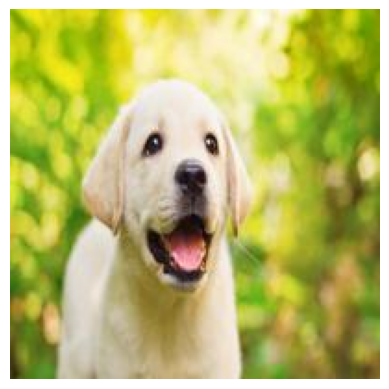

In [7]:
from PIL import Image
import matplotlib.pyplot as plt

img = Image.open("images/dog_image.jpg")

plt.imshow(img)
plt.axis("off")
plt.show()

In [4]:
import os

os.makedirs("images", exist_ok=True)

uploaded_name = list(uploaded.keys())[0]

with open("images/dog_image.jpg", "wb") as f:
    f.write(uploaded[uploaded_name])

print("Image uploaded successfully!")
print("Original filename:", uploaded_name)

Image uploaded successfully!
Original filename: dog_image (1).jpg


## 1. Import the libraries

In [ ]:
from pathlib import Path

import cv2
import matplotlib.pyplot as plt
import numpy as np
from PIL import Image

PROJECT_DIR = Path.cwd()
IMAGE_PATH = PROJECT_DIR / "images" / "dog_image.jpg"
OUTPUT_DIR = PROJECT_DIR / "outputs"
OUTPUT_DIR.mkdir(exist_ok=True)

if not IMAGE_PATH.exists():
    raise FileNotFoundError(f"Sample image not found: {IMAGE_PATH}")


## 2. Read and inspect the image

In [ ]:
plt.figure(figsize=(6, 4))
plt.imshow(image_array)
plt.title("Original sample image")
plt.axis("off")
plt.show()


In [10]:
from pathlib import Path
from PIL import Image
import numpy as np
import matplotlib.pyplot as plt

PROJECT_DIR = Path.cwd()
IMAGE_PATH = PROJECT_DIR / "images" / "dog_image.jpg"

image = Image.open(IMAGE_PATH).convert("RGB")
image_array = np.array(image)

print("Data type:", type(image_array))
print("Array shape:", image_array.shape)
print("Image size:", image.size)

Data type: <class 'numpy.ndarray'>
Array shape: (200, 200, 3)
Image size: (200, 200)


## 3. Resize the image with Pillow

Original image size: (200, 200)
Resized image size: (150, 150)


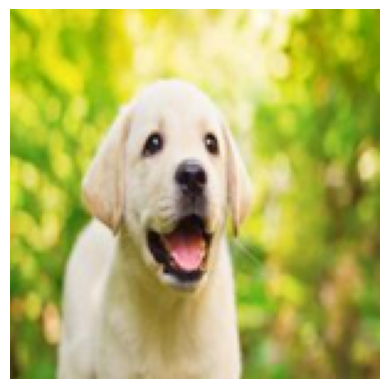

In [11]:
resized_image = image.resize((150, 150))

print("Original image size:", image.size)
print("Resized image size:", resized_image.size)

plt.imshow(resized_image)
plt.axis("off")
plt.show()

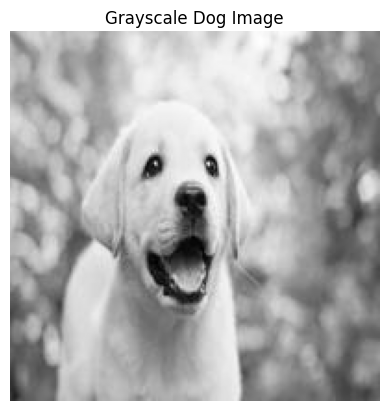

In [12]:
import cv2

# Read the original image
original = cv2.imread("images/dog_image.jpg")

# Convert color image into grayscale
gray_image = cv2.cvtColor(original, cv2.COLOR_BGR2GRAY)

# Display grayscale image
plt.imshow(gray_image, cmap="gray")
plt.title("Grayscale Dog Image")
plt.axis("off")
plt.show()

In [13]:
cv2.imwrite("outputs/dog_grayscale.jpg", gray_image)

print("Grayscale image saved successfully!")

Grayscale image saved successfully!


In [ ]:
resized_image = image.resize((150, 150), Image.Resampling.LANCZOS)
resized_path = OUTPUT_DIR / "dog_resized_150x150.jpg"
resized_image.save(resized_path, quality=95)

print("Resized image size (width, height):", resized_image.size)
print("Saved to:", resized_path)


In [16]:
from google.colab import files

files.download("dog_grayscale.jpg")

FileNotFoundError: Cannot find file: dog_grayscale.jpg

In [17]:
# Save the grayscale image
cv2.imwrite("/content/dog_grayscale.jpg", gray_image)

# Download it to your computer
from google.colab import files
files.download("/content/dog_grayscale.jpg")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [ ]:
plt.figure(figsize=(5, 5))
plt.imshow(resized_image)
plt.title("Resized image (150 × 150)")
plt.axis("off")
plt.show()


## 4. Convert the image to grayscale with OpenCV

In [ ]:
# OpenCV reads color images in BGR channel order.
bgr_image = cv2.imread(str(IMAGE_PATH))
if bgr_image is None:
    raise ValueError(f"OpenCV could not read the image: {IMAGE_PATH}")

gray_image = cv2.cvtColor(bgr_image, cv2.COLOR_BGR2GRAY)
gray_path = OUTPUT_DIR / "dog_grayscale.jpg"

if not cv2.imwrite(str(gray_path), gray_image):
    raise IOError(f"Could not save grayscale image: {gray_path}")

print("Original OpenCV shape:", bgr_image.shape)
print("Grayscale shape:", gray_image.shape)
print("Saved to:", gray_path)


In [ ]:
plt.figure(figsize=(6, 4))
plt.imshow(gray_image, cmap="gray")
plt.title("Grayscale image")
plt.axis("off")
plt.show()


## 5. Compare the results

- **Original image:** three color channels (height, width, 3).
- **Resized image:** the same content scaled to 150 × 150 pixels.
- **Grayscale image:** one intensity channel (height, width).

## 6. What you learned

This exercise demonstrates basic image preprocessing operations commonly used before training computer vision and deep learning models.

**Next steps:** experiment with different image sizes, apply Gaussian blur, detect edges with Canny, and later explore image classification.

## Notes

- Open the notebook from the project directory so the relative image path resolves correctly.
- OpenCV uses BGR ordering for color images loaded with `cv2.imread`; therefore, `cv2.COLOR_BGR2GRAY` is used here.
- This is a foundational learning project, not a trained machine learning model.
